# Qualitative samples for the thesis -- Colab

Small, controlled examples and plots for the write-up (not evaluation -- no scoring here).

First artefact: a **cross-attention heatmap** + alignment table on a short span-denoising
example, plus a readable view of the encoder output, for the *Encoder-Decoder Backbone*
section of `Architecture.tex`. The eval-notebook heatmaps are unreadable because they run on
full-length samples; here the input is one short function on purpose.

Two decode modes are provided:
* **teacher-forced** (#04) -- decoder fed the reference target; clean and reproducible, but shows
  only the attention *mechanism*, not the model solving anything.
* **free / greedy** (#07) -- the model's own generation; use this for the thesis figure **if the
  model reconstructs the example correctly**, so the figure shows a real solve.

**Before running:** upload the project to Drive at `My Drive/TLM_V03/` with `src/`,
`data/checkpoints/<RUN_NAME>/` (current-vocab checkpoint), and `Thesis/images/`.

## 01 -- Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import sys, re, random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

DRIVE_ROOT = Path('/content/drive/MyDrive/TLM_V03')
assert DRIVE_ROOT.exists(), f"{DRIVE_ROOT} not found -- upload the project to Drive first"
sys.path.insert(0, str(DRIVE_ROOT))

from src.model_config import ModelConfig
from src.model_variants import TLM_S
from src.tokenizer import TLM_Tokenizer
from src.data_set import make_sr_corruption
from src.inference.generate import greedy_decode

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

MODEL_SIZE = 'S'                     # 'XS' | 'S' | 'M' -- must match the checkpoint
RUN_NAME   = 'tlm_s_pretrain'        # checkpoint dir under data/checkpoints/

_LADDER = {
    'XS': dict(d_model=128, d_ff=512,  target_param_count=3_130_000),
    'S':  dict(d_model=192, d_ff=768,  target_param_count=5_000_000),
    'M':  dict(d_model=256, d_ff=1024, target_param_count=9_500_000),
}

CKPT_DIR       = DRIVE_ROOT / 'data' / 'checkpoints' / RUN_NAME
TOKENIZER_PATH = str(DRIVE_ROOT / 'src' / 'tokenizer' / 'tokenizer_tlm_small.json')
OUT_DIR        = DRIVE_ROOT / 'Thesis' / 'images'
OUT_DIR.mkdir(parents=True, exist_ok=True)

print('device:', device, '| size:', MODEL_SIZE, '| run:', RUN_NAME)
print('figures ->', OUT_DIR)

Mounted at /content/drive
[tlm_s.py] Loaded TLM_S model variant
device: cuda | size: S | run: tlm_s_pretrain
figures -> /content/drive/MyDrive/TLM_V03/Thesis/images


## 02 -- Load model + tokenizer

In [2]:
def _val_from_name(p):
    m = re.search(r'val([0-9.]+)\.pt$', p.name)
    return float(m.group(1)) if m else float('inf')

_ckpts = sorted(CKPT_DIR.glob(f'{RUN_NAME}_epoch_*_val*.pt'))
assert _ckpts, f'no checkpoints in {CKPT_DIR}'
CKPT_PATH = min(_ckpts, key=_val_from_name)
print('using', CKPT_PATH.name)

config = ModelConfig(**_LADDER[MODEL_SIZE])   # n_task_types=6, vocab 10k
model = TLM_S(config)

state = torch.load(CKPT_PATH, map_location=device)
state_dict = state['model'] if isinstance(state, dict) and 'model' in state else state
model.load_state_dict(state_dict)
model.to(device).eval()

if isinstance(state, dict):
    print('epoch:', state.get('epoch'), '| val_loss:', state.get('val_loss', state.get('best_val')))

tok = TLM_Tokenizer()
tok.load(TOKENIZER_PATH)
print('tokenizer vocab:', tok.vocab_size)

using tlm_s_pretrain_epoch_20_val0.1778.pt
[tlm_s.py] Initialized TLM_S model variant with 6069697 parameters
epoch: 20 | val_loss: 0.17779150915439013
tokenizer vocab: 10000


## 03 -- Build a short span-denoising example

`make_sr_corruption` masks random spans, so we seed it and keep the first result short enough to
plot. Change `SEED` / `CODE` / the caps until you get one you like -- fully reproducible.

In [3]:
CODE = "def area(radius):\n    pi = 3.14159\n    return pi * radius * radius\n"
SEED = 3
MAX_ENC, MAX_DEC = 40, 45

random.seed(SEED)
enc_ids = dec_ids = None
for _ in range(200):
    r = make_sr_corruption(CODE, tok, config)
    if r and len(r[0]) <= MAX_ENC and len(r[1]) <= MAX_DEC:
        enc_ids, dec_ids = r
        break
assert enc_ids is not None, 'no short-enough corruption found -- raise the caps or change SEED'

enc_toks = [tok.id_to_token(i) for i in enc_ids]
dec_toks = [tok.id_to_token(i) for i in dec_ids]
print('encoder input  ({:2d}):'.format(len(enc_toks)), ' '.join(enc_toks))
print('decoder target ({:2d}):'.format(len(dec_toks)), ' '.join(dec_toks))

encoder input  (28): <bos> def</w> <extra_id_0> (</w> radi us</w> )</w> :</w> <newline> <indent> pi</w> =</w> 3. 14 15 9</w> <newline> return</w> <extra_id_1> *</w> radi us</w> *</w> radi us</w> <newline> <dedent> <eos>
decoder target (37): <bos> <search> def</w> <extra_id_0> (</w> radi us</w> )</w> :</w> <replace> def</w> are a</w> (</w> radi us</w> )</w> :</w> <search> return</w> <extra_id_1> *</w> radi us</w> *</w> radi us</w> <replace> return</w> pi</w> *</w> radi us</w> *</w> radi us</w> <eos>


## Shared helpers -- heatmap + alignment table

In [4]:
def plot_cross_attention(ca, row_labels, col_labels, out_path=None, title=None,
                         ylabel='decoder step'):
    """Heatmap: decoder step (row) x encoder token (col). ca in [0, 1], rows sum ~1."""
    n_rows, n_cols = ca.shape
    fig, ax = plt.subplots(figsize=(0.34 * n_cols + 2.5, 0.34 * n_rows + 1.5))
    im = ax.imshow(ca, aspect='auto', cmap='Blues', vmin=0.0, vmax=1.0)
    ax.set_xticks(range(n_cols)); ax.set_xticklabels(col_labels, rotation=90, fontsize=8)
    ax.set_yticks(range(n_rows)); ax.set_yticklabels(row_labels, fontsize=8)
    ax.set_xlabel('encoder tokens'); ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title, fontsize=10)
    ax.set_xticks(np.arange(-0.5, n_cols, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_rows, 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=0.5)
    ax.tick_params(which='minor', length=0)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label='attention weight')
    fig.tight_layout()
    if out_path:
        fig.savefig(out_path, dpi=200, bbox_inches='tight')
        print('saved', out_path)
    return fig


def alignment_table(ca, row_labels, col_labels):
    """One row per emitted token: which SEARCH/REPLACE block it is in, the encoder
    position it attended to most, the weight there, and whether that emitted token
    also occurs somewhere in the encoder input (i.e. was copyable). Eyeball this and
    hand-pick a few rows: SEARCH tokens copying the corrupted line verbatim, and the
    two sentinels' REPLACE reconstructions -- one that could be copied from elsewhere
    in the source, one that had to be generated."""
    top = ca.argmax(axis=1)
    block, cur = [], '-'
    for t in row_labels:
        if t == '<search>':
            cur = 'SEARCH'
        elif t == '<replace>':
            cur = 'REPLACE'
        block.append(cur)
    enc_set = set(col_labels)
    return pd.DataFrame({
        'step':       range(len(row_labels)),
        'block':      block,
        'emitted':    row_labels,
        'attends_to': [col_labels[j] for j in top],
        'enc_pos':    top,
        'weight':     [round(float(ca[t, j]), 2) for t, j in enumerate(top)],
        'in_source':  [t in enc_set for t in row_labels],
    })

## 04 -- Teacher-forced pass

One `encode`, one `decode_full` on the reference target. Deterministic; shows the attention
*mechanism* but not a solve (the decoder is fed the answer, including the sentinels).

saved /content/drive/MyDrive/TLM_V03/Thesis/images/backbone_cross_attn.png


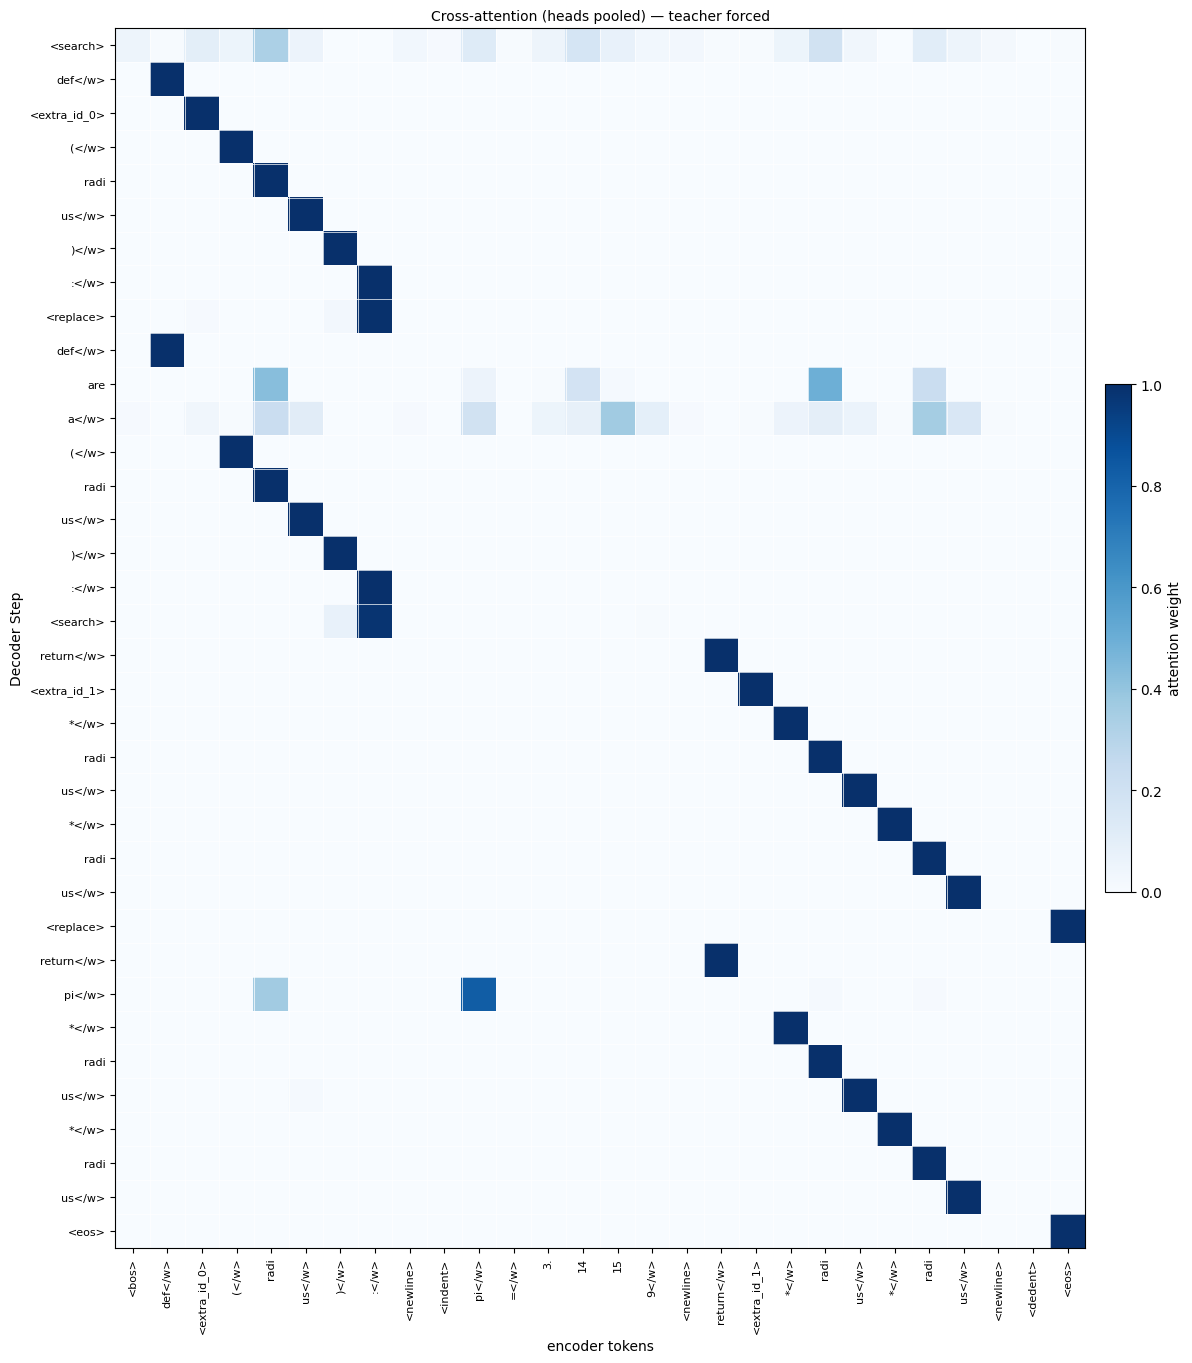

,step,block,emitted,attends_to,enc_pos,weight,in_source
0,0,SEARCH,<search>,radi,4,0.33,False
1,1,SEARCH,def</w>,def</w>,1,1.00,True
2,2,SEARCH,<extra_id_0>,<extra_id_0>,2,1.00,True
3,3,SEARCH,(</w>,(</w>,3,1.00,True
4,4,SEARCH,radi,radi,4,1.00,True
5,5,SEARCH,us</w>,us</w>,5,1.00,True
6,6,SEARCH,)</w>,)</w>,6,1.00,True
7,7,SEARCH,:</w>,:</w>,7,1.00,True
8,8,REPLACE,<replace>,:</w>,7,0.99,False
9,9,REPLACE,def</w>,def</w>,1,1.00,True


In [5]:
TASK_ID = 0  # 0 = pretrain / span denoising

enc_t = torch.tensor([enc_ids], dtype=torch.long, device=device)
dec_t = torch.tensor([dec_ids], dtype=torch.long, device=device)
enc_attn = torch.ones_like(enc_t)
task_t = torch.tensor([TASK_ID], dtype=torch.long, device=device)

with torch.no_grad():
    enc_out, enc_mask = model.encode(enc_t, enc_attn=enc_attn, task_ids=task_t)
    out = model.decode_full(enc_out, enc_mask, enc_t, dec_t, use_copy=True)

enc_repr = enc_out[0].float().cpu().numpy()        # (enc_len, d_model)
ca_tf    = out['ca_w'][0].float().cpu().numpy()[:-1]   # drop last row (no token after it)
pgen_tf  = out['p_gen'][0].float().cpu().numpy()[:-1]  # copy gate per emitted token
tf_rows  = dec_toks[1:]

plot_cross_attention(ca_tf, tf_rows, enc_toks, ylabel='Decoder Step',
                     out_path=OUT_DIR / 'backbone_cross_attn.png',
                     title='Cross-attention (heads pooled) -- teacher forced')
plt.show()
alignment_table(ca_tf, tf_rows, enc_toks)

## 05 -- Encoder output, made readable

One vector per token. Nothing to "read" in the raw 192 numbers, so: (a) the matrix as a heatmap,
one column per token; (b) the L2 norm per position, the one scalar per token easy to talk about.

saved /content/drive/MyDrive/TLM_V03/Thesis/images/backbone_encoder_output.png


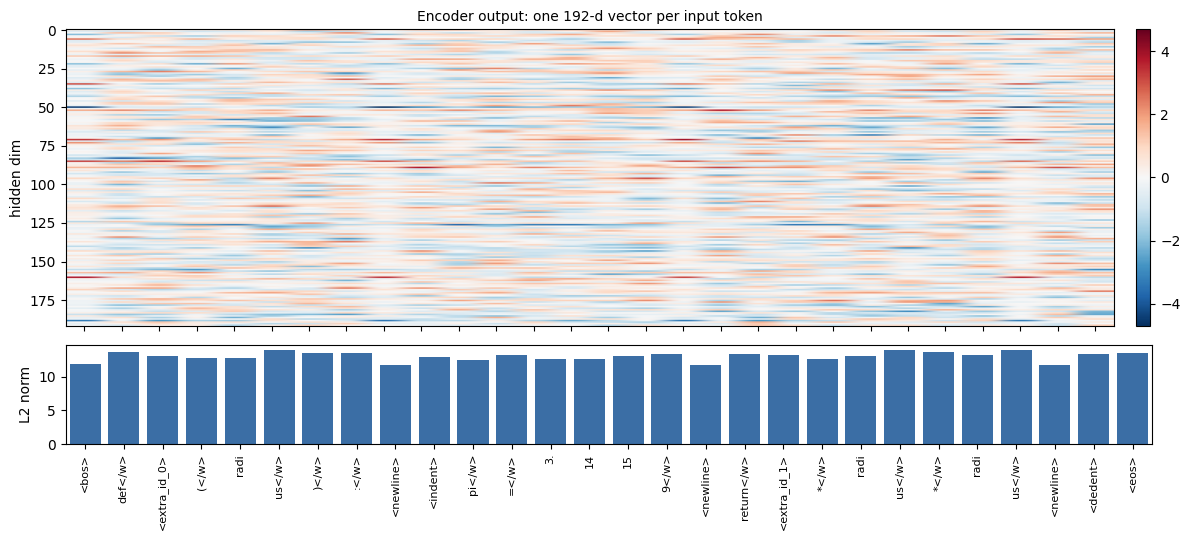

In [6]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(0.34 * len(enc_toks) + 2.5, 5.5),
    gridspec_kw={'height_ratios': [3, 1]}, sharex=True,
)
v = float(np.abs(enc_repr).max())
im = ax1.imshow(enc_repr.T, aspect='auto', cmap='RdBu_r', vmin=-v, vmax=v)
ax1.set_ylabel('hidden dim')
ax1.set_title('Encoder output: one {}-d vector per input token'.format(enc_repr.shape[1]), fontsize=10)
fig.colorbar(im, ax=ax1, fraction=0.015, pad=0.02)

norms = np.linalg.norm(enc_repr, axis=1)
ax2.bar(range(len(enc_toks)), norms, color='#3b6ea5')
ax2.set_ylabel('L2 norm')
ax2.set_xticks(range(len(enc_toks)))
ax2.set_xticklabels(enc_toks, rotation=90, fontsize=8)

fig.tight_layout()
fig.savefig(OUT_DIR / 'backbone_encoder_output.png', dpi=200, bbox_inches='tight')
print('saved', OUT_DIR / 'backbone_encoder_output.png')
plt.show()

## 06 -- Free / greedy decode  --  the one for the thesis figure

The model generates on its own. Check `stop_reason == 'eos'` and that `decoded` matches the
intended reconstruction -- if so, this heatmap shows the mechanism **and** a real solve. Pick a
`SEED` in #03 where the model gets it right.

`ca_w` here is `(steps, enc_len)` -- rows are the tokens the model actually emitted.

stop_reason: eos
generated  : <bos> <search> def</w> <extra_id_0> (</w> radi us</w> )</w> :</w> <replace> def</w> radi us</w> (</w> radi us</w> )</w> :</w> <search> return</w> <extra_id_1> *</w> radi us</w> *</w> radi us</w> <replace> return</w> pi</w> *</w> radi us</w> *</w> radi us</w> <eos>
decoded    :
 def(radius):def radius(radius):return*radius*radiusreturn pi*radius*radius
saved /content/drive/MyDrive/TLM_V03/Thesis/images/backbone_cross_attn_free.png


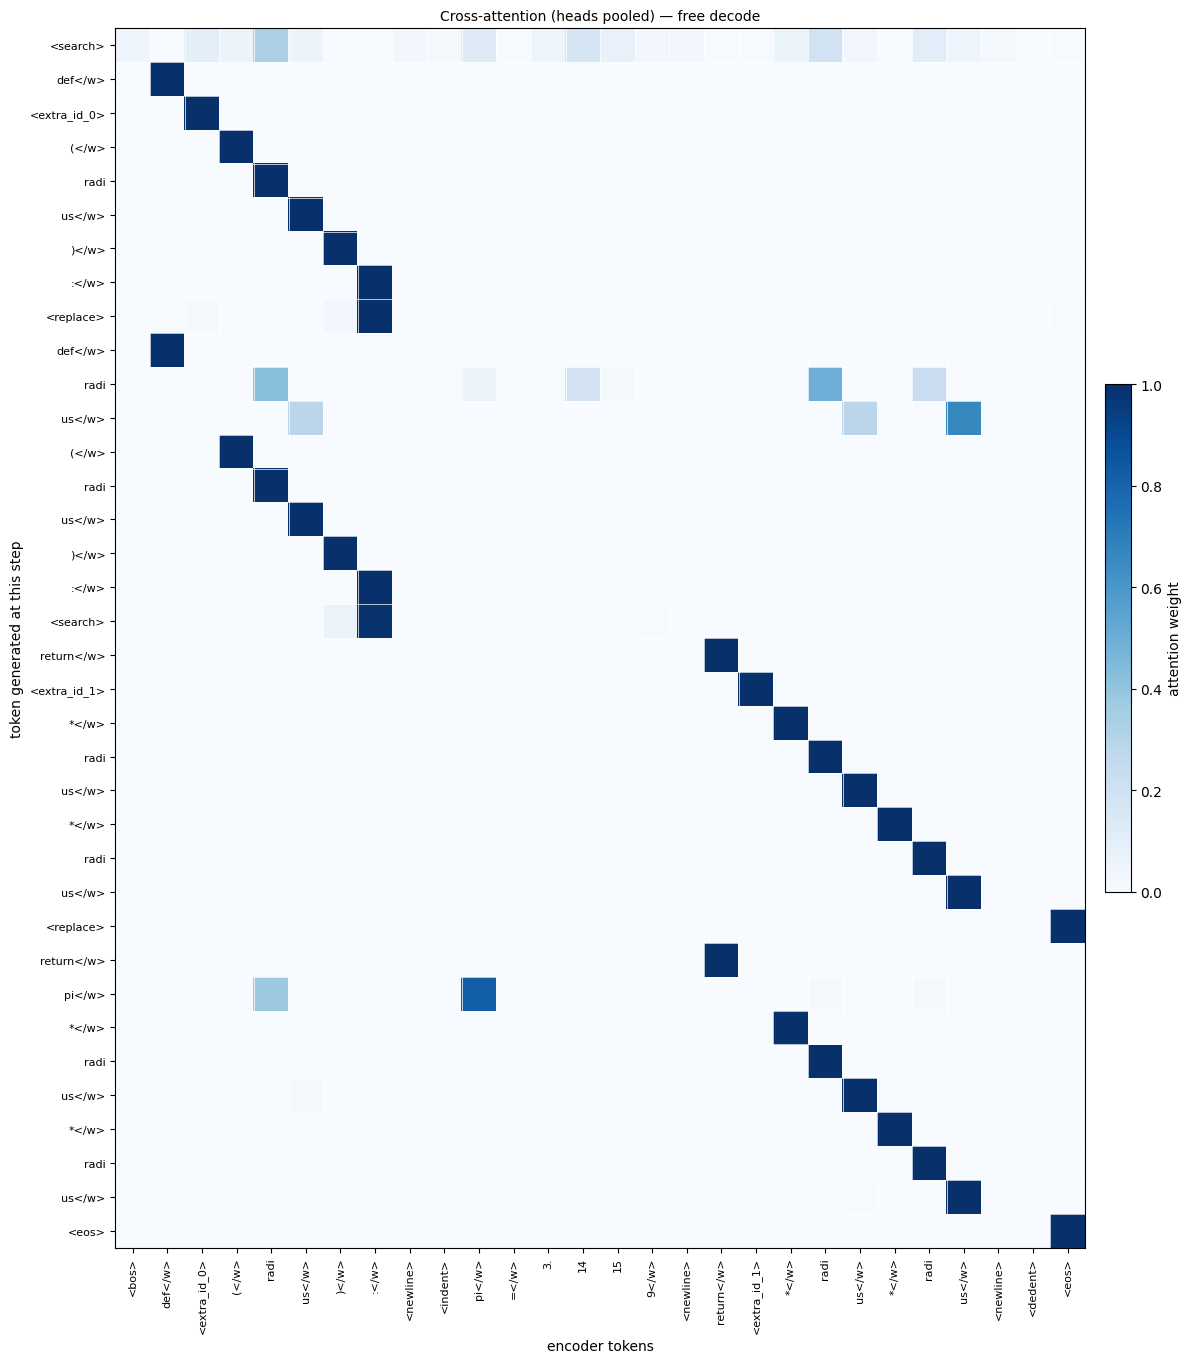

,step,block,emitted,attends_to,enc_pos,weight,in_source
0,0,SEARCH,<search>,radi,4,0.33,False
1,1,SEARCH,def</w>,def</w>,1,1.00,True
2,2,SEARCH,<extra_id_0>,<extra_id_0>,2,1.00,True
3,3,SEARCH,(</w>,(</w>,3,1.00,True
4,4,SEARCH,radi,radi,4,1.00,True
5,5,SEARCH,us</w>,us</w>,5,1.00,True
6,6,SEARCH,)</w>,)</w>,6,1.00,True
7,7,SEARCH,:</w>,:</w>,7,1.00,True
8,8,REPLACE,<replace>,:</w>,7,0.99,False
9,9,REPLACE,def</w>,def</w>,1,1.00,True


In [7]:
g = greedy_decode(model, enc_ids, TASK_ID, device, collect_attn=True, collect_pgen=True)
gen_toks = [tok.id_to_token(i) for i in g['tokens']]
print('stop_reason:', g['stop_reason'])
print('generated  :', ' '.join(gen_toks))
print('decoded    :\n', tok.decode(g['tokens']))

ca_gen   = g['ca_w']                         # (steps, enc_len)
gen_rows = gen_toks[1:1 + ca_gen.shape[0]]   # emitted tokens, aligned to rows

if ca_gen.shape[0]:
    plot_cross_attention(ca_gen, gen_rows, enc_toks, ylabel='token generated at this step',
                         out_path=OUT_DIR / 'backbone_cross_attn_free.png',
                         title='Cross-attention (heads pooled) -- free decode')
    plt.show()

align = alignment_table(ca_gen, gen_rows, enc_toks) if ca_gen.shape[0] else None
align

## 07 - Copy gate over the sample  (Appendix: Copy vs Generate)

`p_gen` per emitted token, teacher-forced pass. NOTE: on this checkpoint the gate parks
around 0.6 whether the step copies or generates -- it does not switch. This figure is for the
appendix analysis of the gate, **not** the Methods Copy Mechanism section.


saved /content/drive/MyDrive/TLM_V03/Thesis/images/copy_pgen.png


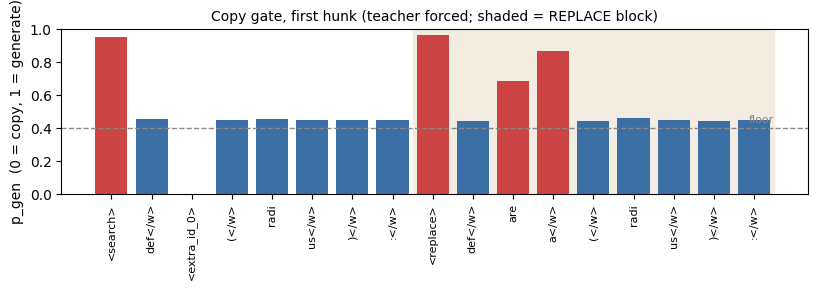

saved /content/drive/MyDrive/TLM_V03/Thesis/images/appendix_copy_pgen.png


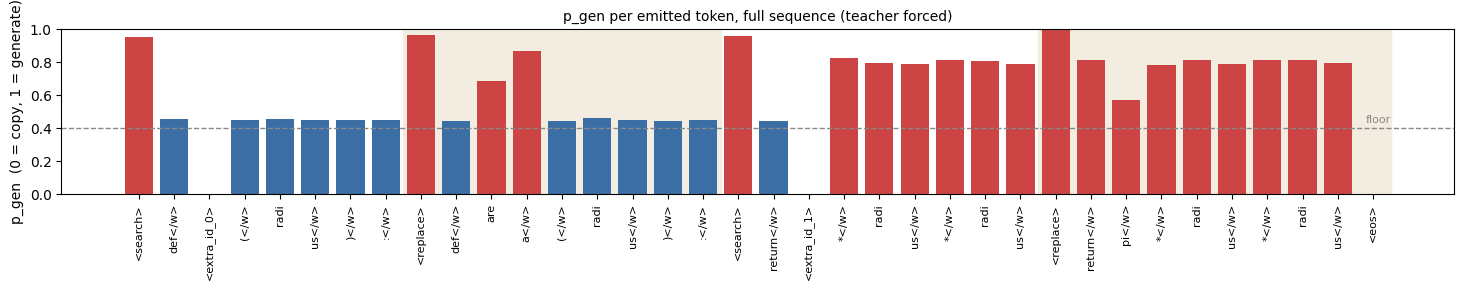

,step,block,emitted,p_gen,copy_attn_max
0,0,S,<search>,0.96,0.33
1,1,S,def</w>,0.45,1.00
2,2,S,<extra_id_0>,0.00,1.00
3,3,S,(</w>,0.45,1.00
4,4,S,radi,0.46,1.00
5,5,S,us</w>,0.45,1.00
6,6,S,)</w>,0.45,1.00
7,7,S,:</w>,0.45,1.00
8,8,R,<replace>,0.96,0.99
9,9,R,def</w>,0.45,1.00


mean p_gen: 0.62 | SEARCH: 0.58 | REPLACE: 0.65


In [8]:
PGEN_FLOOR = 0.4  # src/training/training.py -- one-sided floor, lambda=0.1

steps = list(tf_rows)
blk, cur = [], '-'
for t in steps:
    if t == '<search>':
        cur = 'S'
    elif t == '<replace>':
        cur = 'R'
    blk.append(cur)

# first hunk ends at the second <search>
h1_end = next((i for i, t in enumerate(steps) if t == '<search>' and i > 0), len(steps))


def pgen_bar(rng, out_path, title):
    xs = list(rng)
    vals = [pgen_tf[i] for i in xs]
    fig, ax = plt.subplots(figsize=(0.34 * len(xs) + 2.5, 3.0))
    ax.bar(range(len(xs)), vals, color=['#c44' if v >= 0.5 else '#3b6ea5' for v in vals])
    ax.axhline(PGEN_FLOOR, ls='--', lw=1, color='#888')
    ax.text(len(xs) - 0.5, PGEN_FLOOR + 0.02, 'floor', ha='right', va='bottom', fontsize=8, color='#888')
    for k, i in enumerate(xs):
        if blk[i] == 'R':
            ax.axvspan(k - 0.5, k + 0.5, color='#f2ede0', zorder=0)
    ax.set_ylim(0, 1)
    ax.set_ylabel('p_gen  (0 = copy, 1 = generate)')
    ax.set_xticks(range(len(xs)))
    ax.set_xticklabels([steps[i] for i in xs], rotation=90, fontsize=8)
    ax.set_title(title, fontsize=10)
    fig.tight_layout()
    fig.savefig(out_path, dpi=200, bbox_inches='tight')
    print('saved', out_path)
    plt.show()


# Methods figure: first hunk only
pgen_bar(range(h1_end), OUT_DIR / 'copy_pgen.png',
         'Copy gate, first hunk (teacher forced; shaded = REPLACE block)')

# Appendix figure: whole sequence
pgen_bar(range(len(steps)), OUT_DIR / 'appendix_copy_pgen.png',
         'p_gen per emitted token, full sequence (teacher forced)')

top_w = ca_tf.max(axis=1)
detail = pd.DataFrame({
    'step':          range(len(steps)),
    'block':         blk,
    'emitted':       steps,
    'p_gen':         [round(float(v), 2) for v in pgen_tf],
    'copy_attn_max': [round(float(w), 2) for w in top_w],
})
with pd.option_context('display.max_rows', None):
    display(detail)

s  = [pgen_tf[i] for i in range(len(steps)) if blk[i] == 'S']
rr = [pgen_tf[i] for i in range(len(steps)) if blk[i] == 'R']
print('mean p_gen: {:.2f} | SEARCH: {:.2f} | REPLACE: {:.2f}'.format(
    float(np.mean(pgen_tf)), float(np.mean(s)), float(np.mean(rr))))


## 08 -- Coverage penalty: before / after (one example)

A controlled A/B for the *Coverage Penalty* section of `Architecture.tex`. Two SFT checkpoints
trained from the **same** bridging checkpoint on the **same** data with the **same** optimizer
settings -- the only difference is `COVERAGE_LAMBDA`:

| role | checkpoint | `COVERAGE_LAMBDA` |
|---|---|---|
| **before** | `tlm_s_sft/tlm_s_sft_epoch_20_val0.1910.pt` | 0.0 (term absent) |
| **after**  | `tlm_s_sft_coverage/tlm_s_sft_coverage_epoch_25_val0.1904.pt` | 1.0 |

Both are current-vocab and both predate the `compute_loss_free_pgen` copy-gate change -- an
*illustrative* comparison from the S-scale coverage experiment, caption it that way.

The failure the penalty targets: the decoder swings **backward** to re-attend an
encoder span it already consumed and emits a **duplicate SEARCH/REPLACE hunk** instead of
advancing. `08b` decodes both models with the repeat guard **off** and keeps samples where
the *before* output repeats a hunk and the *after* output repeats strictly fewer while still
applying to the source (exact gold match preferred). `08c` prints each candidate as readable
SEARCH/REPLACE hunks and writes `Thesis/snippets/coverage_before_after.txt`.

`TARGET_TASK` in `08b` is `rename` by default; if no clean rename pair turns up, switch it to
`deduplicate` or `extract_method`, where the repetition-collapse is more pronounced.

The three `Architecture.tex` listings for the picked `[k]`: **SOURCE (input program)**,
**NO coverage penalty hunks**, **WITH coverage penalty hunks**. `08d` saves the two
cross-attention heatmaps as `images/no_coverage.png` and `images/with_coverage.png`.

**Extra upload:** both checkpoints above on Drive, plus
`data/finetune_data/sft_val_domain.jsonl`.

In [9]:
# 08a -- load both SFT checkpoints (before = no coverage, after = coverage lambda=1.0)
from src.data_set import make_sft_sr, split_lines_by_newline, join_lines

BEFORE_CKPT = DRIVE_ROOT / 'data' / 'checkpoints' / 'tlm_s_sft'          / 'tlm_s_sft_epoch_20_val0.1910.pt'
AFTER_CKPT  = DRIVE_ROOT / 'data' / 'checkpoints' / 'tlm_s_sft_coverage' / 'tlm_s_sft_coverage_epoch_25_val0.1904.pt'
for p in (BEFORE_CKPT, AFTER_CKPT):
    assert p.exists(), f'missing checkpoint: {p}'


def _load_sft(ckpt_path):
    m = TLM_S(ModelConfig(**_LADDER['S']))
    st = torch.load(ckpt_path, map_location=device)
    m.load_state_dict(st['model'] if isinstance(st, dict) and 'model' in st else st)
    return m.to(device).eval()


model_before = _load_sft(BEFORE_CKPT)
model_after  = _load_sft(AFTER_CKPT)
print('loaded  before:', BEFORE_CKPT.name)
print('loaded  after :', AFTER_CKPT.name)

_EOS_ID = config.special_token_ids['eos']
REPEAT_REASONS = ('repeat_hunk', 'repeat_hunk_at_eos', 'repeat_token_k1', 'repeat_token_k2',
                  'repeat_token_k3', 'repeat_line_k1', 'repeat_line_k2', 'repeat_line_k3')

[tlm_s.py] Initialized TLM_S model variant with 6069697 parameters
[tlm_s.py] Initialized TLM_S model variant with 6069697 parameters
loaded  before: tlm_s_sft_epoch_20_val0.1910.pt
loaded  after : tlm_s_sft_coverage_epoch_25_val0.1904.pt


In [10]:
# # 08b -- scan for a clean before/after pair.
# #   keep: before repeats a SEARCH/REPLACE hunk, after repeats strictly fewer (ideally none),
# #         and after actually applies to the source (prefer an exact gold match).
# import json

# SFT_VAL_PATH = DRIVE_ROOT / 'data' / 'finetune_data' / 'sft_val_domain.jsonl'
# assert SFT_VAL_PATH.exists(), f'missing {SFT_VAL_PATH}'

# records = [json.loads(l) for l in SFT_VAL_PATH.read_text(encoding='utf-8').splitlines() if l.strip()]
# by_type = {}
# for d in records:
#     by_type.setdefault(d.get('type'), []).append(d)
# print({k: len(v) for k, v in by_type.items()})

# from src.data_set import apply_sr

# _SEARCH_ID  = config.special_token_ids['search']
# _REPLACE_ID = config.special_token_ids['replace']
# _BOS_ID     = config.special_token_ids['bos']

# TARGET_TASK = 'rename'          # 'rename' | 'deduplicate' | 'extract_method'
# MIN_HUNKS, MAX_HUNKS = 3, 8
# N_KEEP   = 12
# MAX_SCAN = 750


# def sr_pairs(ids):
#     """[(search_text, replace_text), ...] from a token-id list (gold or generated)."""
#     body = [t for t in ids if t not in (_BOS_ID, _EOS_ID)]
#     pairs, i = [], 0
#     while i < len(body):
#         if body[i] != _SEARCH_ID:
#             i += 1; continue
#         i += 1; s0 = i
#         while i < len(body) and body[i] != _REPLACE_ID:
#             i += 1
#         s_ids = body[s0:i]
#         i += 1; r0 = i
#         while i < len(body) and body[i] != _SEARCH_ID:
#             i += 1
#         pairs.append((tok.decode(s_ids).strip(), tok.decode(body[r0:i]).strip()))
#     return pairs


# def render_sr(pairs):
#     if not pairs:
#         return '(no SEARCH/REPLACE hunks parsed)'
#     out = []
#     for j, (s, r) in enumerate(pairs, 1):
#         out.append(f'  hunk {j}\n    SEARCH  {s!r}\n    REPLACE {r!r}')
#     return '\n'.join(out)


# def n_dup_hunks(pairs):
#     return len(pairs) - len(set(pairs))


# def after_status(before_text, pred_tokens, gold_after_text):
#     pa = apply_sr(tok.encode(before_text), pred_tokens, config)
#     if pa is None:
#         return 'apply_failed'
#     return 'exact' if tok.decode(pa).strip() == gold_after_text.strip() else 'differs'


# def decode_both(enc_ids, task_id, guard):
#     kw = dict(collect_conf=False, stop_on_repeat_hunk=guard)
#     return (greedy_decode(model_before, enc_ids, task_id, device, **kw),
#             greedy_decode(model_after,  enc_ids, task_id, device, **kw))


# matches = []
# for d in by_type.get(TARGET_TASK, [])[:MAX_SCAN]:
#     if len(matches) >= N_KEEP:
#         break
#     res = make_sft_sr(d, tok, config)
#     if res is None:
#         continue
#     enc_ids, gold_ids, task_id = res
#     gp = sr_pairs(gold_ids)
#     if not (MIN_HUNKS <= len(gp) <= MAX_HUNKS):
#         continue
#     gb, ga = decode_both(enc_ids, task_id, guard=False)
#     bp, ap = sr_pairs(gb['tokens']), sr_pairs(ga['tokens'])
#     b_dup, a_dup = n_dup_hunks(bp), n_dup_hunks(ap)
#     a_stat = after_status(d['before'], ga['tokens'], d['after'])
#     if b_dup >= 1 and a_dup < b_dup and a_stat != 'apply_failed':
#         matches.append(dict(
#             ttype=TARGET_TASK, d=d, enc_ids=enc_ids, gold_ids=gold_ids, task_id=task_id,
#             n_hunks=len(gp), src_len=len(d['before']), b_dup=b_dup, a_dup=a_dup,
#             after_stat=a_stat, before_stop=gb['stop_reason'], after_stop=ga['stop_reason']))
#         print(f"  match {len(matches)}/{N_KEEP}  n_hunks={len(gp)}  "
#               f"dup_hunks before={b_dup} after={a_dup}  after={a_stat}  src_len={len(d['before'])}")

# matches.sort(key=lambda m: (m['after_stat'] != 'exact', m['a_dup'], m['n_hunks'], m['src_len']))
# print(f'\n{len(matches)} candidate pair(s), best first. If 0, set TARGET_TASK to '
#       "'deduplicate' or 'extract_method' (stronger repetition-collapse cases) and rerun.")

In [11]:
# # 08c -- render candidates as readable SEARCH/REPLACE hunks (guard OFF), save to a file.
# #        Hand-pick the [k] with a clean "before" loop and a correct, non-repeating "after".
# SNIP_DIR = DRIVE_ROOT / 'Thesis' / 'snippets'
# SNIP_DIR.mkdir(parents=True, exist_ok=True)


# def _section(title, body):
#     return f'----- {title} -----\n{body}\n'


# blocks = []
# for k, m in enumerate(matches):
#     gb, ga = decode_both(m['enc_ids'], m['task_id'], guard=False)
#     gp, bp, ap = sr_pairs(m['gold_ids']), sr_pairs(gb['tokens']), sr_pairs(ga['tokens'])

#     hdr = (f"[{k}] {m['ttype']}  gold_hunks={m['n_hunks']}  "
#            f"before: {len(bp)} hunks / {m['b_dup']} repeated / {gb['stop_reason']} / "
#            f"{after_status(m['d']['before'], gb['tokens'], m['d']['after'])}  ||  "
#            f"after: {len(ap)} hunks / {m['a_dup']} repeated / {ga['stop_reason']} / {m['after_stat']}")
#     block = '\n'.join([
#         '=' * 100, hdr, '=' * 100,
#         _section('SOURCE (input program)', m['d']['before'].rstrip()),
#         _section('EXPECTED (gold "after")', m['d']['after'].rstrip()),
#         _section('GOLD hunks', render_sr(gp)),
#         _section('NO coverage penalty (COVERAGE_LAMBDA=0) hunks', render_sr(bp)),
#         _section('WITH coverage penalty (COVERAGE_LAMBDA=1.0) hunks', render_sr(ap)),
#     ])
#     blocks.append(block)
#     print(block, '\n')

# out_txt = SNIP_DIR / 'coverage_before_after.txt'
# out_txt.write_text('\n\n'.join(blocks) if blocks else '(no candidates)', encoding='utf-8')
# print('saved ->', out_txt)
# print('\nSet PICK in 08d to the [k] you want; the three Architecture.tex listings are its '
#       'SOURCE block and the two "... hunks" blocks.')

In [12]:
# # 08d -- cross-attention heatmaps for one matched pair. Left = no coverage (backward
# #        re-attention / repeated hunk), right = coverage (forward-advancing). Set PICK from 08c.
# #        Filenames match \includegraphics in Thesis/Architecture.tex (sec:coverage).
# PICK = 0
# m = matches[PICK]
# enc_toks_cov = [tok.id_to_token(i) for i in m['enc_ids']]

# gb = greedy_decode(model_before, m['enc_ids'], m['task_id'], device,
#                    collect_conf=False, collect_attn=True, stop_on_repeat_hunk=False)
# ga = greedy_decode(model_after,  m['enc_ids'], m['task_id'], device,
#                    collect_conf=False, collect_attn=True, stop_on_repeat_hunk=False)

# for fname, title, g in (('no_coverage.png',   'Trained without the coverage penalty', gb),
#                         ('with_coverage.png', 'Trained with the coverage penalty',    ga)):
#     ca = g['ca_w']
#     if not ca.shape[0]:
#         print(fname, '-> no attention steps'); continue
#     rows = [tok.id_to_token(i) for i in g['tokens'][1:1 + ca.shape[0]]]
#     plot_cross_attention(ca, rows, enc_toks_cov, ylabel='token generated at this step',
#                          out_path=OUT_DIR / fname, title=title)
#     plt.show()

# print(f'\nPICK={PICK}  before_stop={gb["stop_reason"]} ({len(gb["tokens"])} tok)  '
#       f'after_stop={ga["stop_reason"]} ({len(ga["tokens"])} tok)')

In [13]:
# # 08e -- rebuild the hunks into full programs for one clean end-to-end view.
# #        First tries the strict applier (apply_sr). When that bails -- which is exactly what
# #        happens on the "before" model here, because a duplicated hunk can't apply twice --
# #        it falls back to a best-effort sequential apply: walk the generated hunks in order,
# #        apply each one that still matches the working program, skip the rest, and report
# #        which hunks were skipped. That gives a readable full program for both sides plus an
# #        honest note of what the strict applier rejected.
# #        Prints SOURCE -> GOLD "after" -> no-coverage -> coverage, and writes
# #        Thesis/snippets/coverage_full_reconstruction.txt
# PICK = 0
# m = matches[PICK]

# gb = greedy_decode(model_before, m['enc_ids'], m['task_id'], device,
#                    collect_conf=False, stop_on_repeat_hunk=False)
# ga = greedy_decode(model_after,  m['enc_ids'], m['task_id'], device,
#                    collect_conf=False, stop_on_repeat_hunk=False)

# src_text  = m['d']['before'].rstrip()
# gold_text = m['d']['after'].rstrip()
# src_ids   = tok.encode(src_text)


# def sr_pairs_ids(ids):
#     """[(search_ids, replace_ids), ...] at the token level (no decode round-trip)."""
#     body = [t for t in ids if t not in (_BOS_ID, _EOS_ID)]
#     pairs, i = [], 0
#     while i < len(body):
#         if body[i] != _SEARCH_ID:
#             i += 1; continue
#         i += 1; s0 = i
#         while i < len(body) and body[i] != _REPLACE_ID:
#             i += 1
#         s_ids = body[s0:i]
#         i += 1; r0 = i
#         while i < len(body) and body[i] != _SEARCH_ID:
#             i += 1
#         pairs.append((s_ids, body[r0:i]))
#     return pairs


# def _find_sub(hay, needle, start=0):
#     if not needle:
#         return -1
#     for p in range(start, len(hay) - len(needle) + 1):
#         if hay[p:p + len(needle)] == needle:
#             return p
#     return -1


# def _best_effort_apply(pred_tokens):
#     """Sequential first-occurrence replace over token ids; skips hunks that no longer match."""
#     work = list(src_ids)
#     cursor, skipped = 0, []
#     for j, (s_ids, r_ids) in enumerate(sr_pairs_ids(pred_tokens), 1):
#         at = _find_sub(work, s_ids, cursor)
#         if at < 0:
#             at = _find_sub(work, s_ids, 0)          # allow out-of-order, still first match
#         if at < 0:
#             skipped.append(j)
#             continue
#         work[at:at + len(s_ids)] = r_ids
#         cursor = at + len(r_ids)
#     return tok.decode(work).strip(), skipped


# def _reconstruct(pred_tokens):
#     applied = apply_sr(src_ids, pred_tokens, config)
#     if applied is not None:
#         text = tok.decode(applied).strip()
#         status = 'exact gold match' if text == gold_text.strip() else 'strict apply, differs from gold'
#         return text, status
#     text, skipped = _best_effort_apply(pred_tokens)
#     note = f'best-effort apply (strict apply_sr rejected it); skipped hunk(s) {skipped}' if skipped \
#         else 'best-effort apply (strict apply_sr rejected it); all hunks placed'
#     if text == gold_text.strip():
#         note += ' -- result still matches gold'
#     return text, note


# before_text, before_stat = _reconstruct(gb['tokens'])
# after_text,  after_stat  = _reconstruct(ga['tokens'])

# sections = [
#     ('SOURCE (input program)', src_text),
#     ('GOLD (expected "after")', gold_text),
#     (f'NO coverage penalty  ({len(sr_pairs(gb["tokens"]))} hunks, '
#      f'{n_dup_hunks(sr_pairs(gb["tokens"]))} repeated, stop={gb["stop_reason"]})  ->  {before_stat}',
#      before_text),
#     (f'WITH coverage penalty  ({len(sr_pairs(ga["tokens"]))} hunks, '
#      f'{n_dup_hunks(sr_pairs(ga["tokens"]))} repeated, stop={ga["stop_reason"]})  ->  {after_stat}',
#      after_text),
# ]

# report = []
# for title, body in sections:
#     report += ['=' * 100, title, '=' * 100, body, '']
# report = '\n'.join(report)
# print(report)

# out_txt = SNIP_DIR / 'coverage_full_reconstruction.txt'
# out_txt.write_text(report, encoding='utf-8')
# print('saved ->', out_txt)


## 09 -- Scorer walk-through: real model predictions

Loads one SFT checkpoint, decodes held-out records with the same pipeline
`score_eval.ipynb` uses
(`make_sft_sr` -> `greedy_decode` / `decode_rename_without_collision` ->
`apply_sr` -> `TASK_SCORERS`), and prints `before` / reference / model
prediction plus the factor breakdown for each. For every task it keeps the
lowest, median, and highest scoring sample from the scan, so any example
picked for `Thesis/Evaluation.tex` has a real prediction behind it. Also
writes `Thesis/snippets/scorer_examples.txt`.

**Point `SFT_*` at the checkpoint whose numbers you report in the Results
chapter.** Needs `data/finetune_data/sft_val_domain.jsonl` and the SFT
checkpoint on Drive.

In [14]:
# 09a -- load one SFT checkpoint + held-out data, define decode_and_score / show
import json, random
from src.model_config import ModelConfig, count_parameters
from src.data_set import make_sft_sr, apply_sr, split_lines_by_newline, join_lines
from src.inference.generate import greedy_decode, decode_rename_without_collision
from src.eval.scorers import TASK_SCORERS, OK_SCORE_THRESHOLD

SFT_VARIANT = "S"                                   # "XS" | "S" | "M" -- must match the checkpoint
SFT_RUN     = "tlm_s_sft_coverage"
SFT_CKPT    = "tlm_s_sft_coverage_epoch_25_val0.1904.pt"

_SFT_CFG = {
    "XS": dict(d_model=128, d_ff=512,  tier_name="TLM_XS", target_param_count=2_420_000),
    "S":  dict(),                                   # ModelConfig() default == TLM-S
    "M":  dict(d_model=256, d_ff=1024, tier_name="TLM_M", target_param_count=9_500_000),
}
sft_config = ModelConfig(**_SFT_CFG[SFT_VARIANT])
sft_model  = TLM_S(sft_config)
_st = torch.load(DRIVE_ROOT / "data" / "checkpoints" / SFT_RUN / SFT_CKPT, map_location=device)
sft_model.load_state_dict(_st["model"] if isinstance(_st, dict) and "model" in _st else _st)
sft_model.to(device).eval()
print(f"SFT model : {SFT_CKPT}  |  {count_parameters(sft_model)/1e6:.3f}M params  |  epoch {_st.get('epoch')}")

sft_tok = TLM_Tokenizer(vocab_size=sft_config.vocab_size)
sft_tok.load(TOKENIZER_PATH)

_EVAL_PATH = DRIVE_ROOT / "data" / "finetune_data" / "sft_val_domain.jsonl"
sft_by_type = {}
for _line in _EVAL_PATH.read_text(encoding="utf-8").splitlines():
    if _line.strip():
        _d = json.loads(_line); sft_by_type.setdefault(_d["type"], []).append(_d)
print("held-out records:", {k: len(v) for k, v in sft_by_type.items()})

_NL_ID  = sft_config.special_token_ids["newline"]
_EOS_ID = sft_config.special_token_ids["eos"]


def decode_and_score(d):
    ttype = d["type"]
    res = make_sft_sr(d, sft_tok, sft_config)
    if res is None:
        return None
    enc_ids, _, task_id = res
    before_ids = sft_tok.encode(d["before"])
    gold_after = join_lines(split_lines_by_newline(sft_tok.encode(d["after"]), _NL_ID), _NL_ID)

    if ttype == "rename":
        out = decode_rename_without_collision(sft_model, enc_ids, task_id, device, before_ids,
                                              sft_tok, sft_config, max_retries=2, collect_conf=False)
    else:
        out = greedy_decode(sft_model, enc_ids, task_id, device, collect_conf=False)
    pred_ids   = out["tokens"]
    pred_after = apply_sr(before_ids, pred_ids, sft_config)

    before_text = sft_tok.decode(before_ids)
    gold_text   = sft_tok.decode(gold_after)
    pred_text   = sft_tok.decode(pred_after) if pred_after is not None else None

    sc  = TASK_SCORERS[ttype](before_text, pred_text, gold_text)
    thr = OK_SCORE_THRESHOLD.get(ttype, 0.999)
    return dict(ttype=ttype, before=before_text, gold=gold_text, pred=pred_text,
                truncated=pred_ids[-1] != _EOS_ID, applied=pred_after is not None,
                score=sc, applied_ok=sc["score"] >= thr, threshold=thr)


def _factors(r):
    return {k: round(v, 3) for k, v in r["score"].items()
            if isinstance(v, (int, float)) and k not in ("score", "complexity")}


def show(r):
    if r is None:
        print("(skipped -- make_sft_sr returned None)"); return
    bar = "-" * 76
    print(bar)
    print(f"{r['ttype']}   score={r['score']['score']:.3f}   applied_ok={r['applied_ok']}"
          f"   (threshold {r['threshold']})")
    print(f"factors: {_factors(r)}   reason: {r['score'].get('reason')}")
    if r["truncated"]:   print("!! truncated (no EOS)")
    if not r["applied"]: print("!! SEARCH span not found in the source -- nothing applied")
    print(bar)
    print("BEFORE:\n"                     + r["before"])
    print("\nGOLD (reference edit):\n"    + r["gold"])
    print("\nMODEL PREDICTION:\n"         + (r["pred"] or "<none>"))
    print(bar)


[tlm_s.py] Initialized TLM_S model variant with 6069697 parameters
SFT model : tlm_s_sft_coverage_epoch_25_val0.1904.pt  |  6.070M params  |  epoch 25
held-out records: {'remove_dead_code': 750, 'rename': 750, 'simplify': 750, 'extract_method': 750, 'deduplicate': 750}


In [15]:
# 09b -- scan held-out records per task, keep lowest / median / highest scoring, print + save
random.seed(0)
TASKS         = ["rename", "simplify", "remove_dead_code", "extract_method", "deduplicate"]
SCAN_PER_TASK = 40                       # ~200 greedy decodes total; a few minutes on GPU

picks = {}
for _t in TASKS:
    _recs = list(sft_by_type.get(_t, []))
    random.shuffle(_recs)
    _scored = [r for r in (decode_and_score(d) for d in _recs[:SCAN_PER_TASK]) if r]
    if not _scored:
        print(f"{_t:16s} -- no scoreable samples"); continue
    _scored.sort(key=lambda r: r["score"]["score"])
    picks[_t] = {"fail": _scored[0], "mid": _scored[len(_scored) // 2], "pass": _scored[-1]}
    print(f"{_t:16s} scanned {len(_scored):3d}   "
          f"score {_scored[0]['score']['score']:.2f} .. {_scored[-1]['score']['score']:.2f}")

for _t, _three in picks.items():
    print("\n" + "#" * 76 + f"\n###  {_t.upper()}\n" + "#" * 76)
    for _label in ("pass", "mid", "fail"):
        print(f"\n>>> {_label.upper()}")
        show(_three[_label])

_out = DRIVE_ROOT / "Thesis" / "snippets" / "scorer_examples.txt"
_out.parent.mkdir(parents=True, exist_ok=True)
with open(_out, "w", encoding="utf-8") as _f:
    _f.write(f"SFT checkpoint: {SFT_CKPT}\n")
    for _t, _three in picks.items():
        for _label in ("pass", "mid", "fail"):
            r = _three[_label]
            _f.write(f"\n{'='*76}\n{_t.upper()}  --  {_label.upper()}\n{'='*76}\n")
            _f.write(f"score={r['score']['score']:.3f}  applied_ok={r['applied_ok']}  "
                     f"factors={_factors(r)}\n\n")
            _f.write("BEFORE:\n" + r["before"] + "\n\nGOLD:\n" + r["gold"]
                     + "\n\nPREDICTION:\n" + (r["pred"] or "<none>") + "\n")
print("\nsaved ->", _out)


rename           scanned  40   score 0.00 .. 1.00
simplify         scanned  40   score 0.00 .. 1.00
remove_dead_code scanned  40   score 0.45 .. 1.00
extract_method   scanned  40   score 0.00 .. 1.00
deduplicate      scanned  40   score 0.00 .. 0.96

############################################################################
###  RENAME
############################################################################

>>> PASS
----------------------------------------------------------------------------
rename   score=1.000   applied_ok=True   (threshold 0.999)
factors: {'localization_recall': 1.0, 'consistency': 1.0, 'non_interference': 1.0, 'executable': 1, 'duplicate_defs': 0}   reason: None
----------------------------------------------------------------------------
BEFORE:
import pandas as pd

def process(df):
    tmp=df[df['val']>0]
    data2=tmp['data'].mean()
    return data2
    
result=process(pd.DataFrame({'val':[1,-2,3,4],'data':[10,20,30,40]}))

GOLD (reference edit):
import pa